# Agent duration benchmark (Muse Spark 1.3, standard)

How long does each chat agent take to answer? Every agent is called the way production calls it: through the LangGraph chat graph (`langgraph_orchestrator/graph.py`), with `muse-spark-1.3` (the standard model) as the model. The same benchmark with `muse-spark-1.2-contributor` is in `muse_spark_1.2_contributor_agent_duration.ipynb`.

For each question the notebook records:
- **total time** of the graph call (routing + agent),
- **model time**: time spent inside Muse calls (measured with a LangChain callback),
- **other time** = total - model (downloads, retrieval, parsing).

**What is real and what is stubbed**

| Part | In this benchmark |
|---|---|
| Muse model calls (weather, documents) | real, over the network |
| Open-Meteo, PAGASA pages, Nominatim geocoding | real, over the network (caches cleared before each timed run) |
| Document search | real FAISS index from `faiss_vectors/` and real embedding model |
| Supabase reads and writes (evacuation centers, reports) | **stubbed**, so database latency is not included |
| OpenRouteService routing | **not available** (no `ORS_API_KEY`), so the route agent times its fallback path |

The agents that call no model (contacts, location, flood risk, ...) show how much of a reply is plain data work.

In [1]:
import os
import statistics
import sys
import time
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "corpus").is_dir())  # repo root, wherever the notebook lives
sys.path.insert(0, str(REPO / "backend"))  # so `agents`, `src`, `langgraph_orchestrator` import
os.chdir(REPO / "backend")  # some agents read files relative to backend/

from dotenv import load_dotenv

load_dotenv(REPO / "backend" / ".env")
assert os.getenv("MUSE_API"), "MUSE_API not found in backend/.env"

# Cross-encoder reranking is switched off for the main run (a 2 GB model); section 5 measures it separately.
os.environ["RERANKER_MODEL"] = "none"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MODEL = "muse-spark-1.3"
BASE_URL = "https://api.meta.ai/v1"
RUNS = 5  # timed runs per question

## 1. The model, with a timer around every call

In [2]:
from langchain_core.callbacks import BaseCallbackHandler
from langchain_openai import ChatOpenAI


class ModelTimer(BaseCallbackHandler):
    """Adds up the time and output tokens of every model call made while it is attached."""

    def __init__(self):
        self.reset()

    def reset(self):
        self.seconds = 0.0
        self.calls = 0
        self.output_tokens = 0
        self._started = {}

    def on_chat_model_start(self, serialized, messages, *, run_id, **kwargs):
        self._started[run_id] = time.perf_counter()

    def on_llm_end(self, response, *, run_id, **kwargs):
        started = self._started.pop(run_id, None)
        if started is not None:
            self.seconds += time.perf_counter() - started
            self.calls += 1
        for generations in response.generations:
            for generation in generations:
                usage = getattr(getattr(generation, "message", None), "usage_metadata", None) or {}
                self.output_tokens += usage.get("output_tokens", 0)

    def on_llm_error(self, error, *, run_id, **kwargs):
        started = self._started.pop(run_id, None)
        if started is not None:
            self.seconds += time.perf_counter() - started
            self.calls += 1


timer = ModelTimer()


def make_llm(reasoning_effort=None):
    """A Muse chat model. ``reasoning_effort`` is minimal / low / medium / high / xhigh, or None for the default."""
    extra = {"reasoning_effort": reasoning_effort} if reasoning_effort else {}
    return ChatOpenAI(
        model=MODEL, base_url=BASE_URL, api_key=os.environ["MUSE_API"],
        timeout=120, max_retries=0,  # no hidden retries: a failure is counted as a failure
        callbacks=[timer], **extra,
    )


llm = make_llm()
start = time.perf_counter()
print(llm.invoke("Say hi in one word.").content, f"({time.perf_counter() - start:.1f} s, includes connection setup)")

Hi (2.0 s, includes connection setup)


## 2. Fixtures: search index and stand-in database
The document agent needs a retriever; the evacuation, report and route agents need Supabase. The retriever is the real FAISS run. The database calls are replaced with small fake data (synthetic evacuation centers near each city centre, no community reports, report writes ignored).

In [3]:
import numpy as np

from src.rag import embeddings, faiss_store
from src.rag.models import Chunk, SearchFilter

FAISS_DIR = REPO / "faiss_vectors"
run_dir = sorted(p for p in FAISS_DIR.iterdir() if p.is_dir())[-1]
index, chunk_records, run_metadata = faiss_store.load_run(run_dir)
assert run_metadata["embedding_model"] == embeddings.model_name()


class FaissRetriever:
    """Stands in for ``HybridRetriever``: dense search over the saved FAISS run (no database, no BM25)."""

    def search(self, query, search_filter: SearchFilter | None = None, k_each=30, k_fused=40):
        vector = np.array([embeddings.embed_query(query)], dtype="float32")
        _, positions = index.search(vector, k_fused)
        chunks = []
        for position in positions[0]:
            record = chunk_records[position]
            if search_filter is None or search_filter.matches(record["metadata"]):
                chunks.append(Chunk(record["doc_id"], record["chunk_idx"], record["content"], record["metadata"]))
        return chunks


retriever = FaissRetriever()
print("index:", run_dir.name, index.ntotal, "vectors")

index: 20261029-213539_multilingual-e5-large 359 vectors


In [4]:
import agents.evacuation_agent as evacuation_module
import agents.flood_zones as flood_zones_module
import agents.report_agent as report_module
from agents.fetch_supabase_open_meteo_datasets import NCR_LOCATIONS

# Synthetic evacuation centers: three per city, a little north, south and east of the city centre.
FAKE_CENTERS = [
    {"name": f"{city.title()} {label} Elementary School", "city": city.title(), "barangay": f"Barangay {number}",
     "capacity": 300 + 50 * number, "lat": lat + dlat, "lng": lng + dlng}
    for city, (lat, lng) in NCR_LOCATIONS.items()
    for number, (label, dlat, dlng) in enumerate([("North", 0.01, 0.0), ("South", -0.01, 0.0), ("East", 0.0, 0.01)], 1)
]


def fake_fetch_centers(conn, city=None, barangay=None, limit=20):
    rows = [c for c in FAKE_CENTERS if not city or c["city"].lower() == city.lower()]
    return rows[:limit]


evacuation_module.fetch_evacuation_centers = fake_fetch_centers
flood_zones_module.fetch_report_points = lambda conn, hours=6, **kwargs: []
report_module.insert_report = lambda *args, **kwargs: None


def fake_connection():
    """Any non-None connection is enough: the database functions above ignore it."""
    return object()

In [5]:
from langgraph_orchestrator.graph import build_graph


def make_graph(model):
    """The production chat graph, with the stand-in retriever and database."""
    return build_graph(model, retriever, checkpointer=None, get_connection=fake_connection)


graph = make_graph(llm)

/home/kenneth28/my_projects/Flood-Gentic/backend/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. The questions
One per agent. `classify_intent` shows which agent the router picks, which must match the agent we mean to time.

In [6]:
from langgraph_orchestrator.intents import classify_intent

QUESTIONS = [
    # (agent we want, question)
    ("emergency", "Tulong! Nalulunod kami sa baha sa Marikina, may bata kaming kasama"),
    ("report", "Report: flooded na ang kalsada sa Barangay Malanday, Marikina, hanggang tuhod ang tubig"),
    ("route", "How do I get to the nearest evacuation center from Marikina?"),
    ("evacuation", "Where is the nearest evacuation center in Pasig?"),
    ("contacts", "What is the hotline number for Quezon City?"),
    ("location", "Marikina"),
    ("flood_risk", "Will Marikina flood today?"),
    ("weather", "Will it rain tomorrow in Quezon City?"),
    ("documents", "How do I prepare my family before a typhoon?"),
]

# The router names documents questions "preparedness"; a bare place name is "general" and goes to location.
EXPECTED_INTENT = {"documents": "preparedness", "location": "general"}
for agent, question in QUESTIONS:
    intent = classify_intent(question)
    wanted = EXPECTED_INTENT.get(agent, agent)
    status = "ok" if intent == wanted else f"MISROUTED (wanted {wanted})"
    print(f"{agent:<11} -> {intent:<12} {status}")

# Measuring the router on its own: it is plain keyword matching.
route_start = time.perf_counter()
for _ in range(1000):
    classify_intent(QUESTIONS[7][1])
print(f"\nclassify_intent: {(time.perf_counter() - route_start):.3f} ms per call")

emergency   -> emergency    ok
report      -> report       ok
route       -> route        ok
evacuation  -> evacuation   ok
contacts    -> contacts     ok
location    -> general      ok
flood_risk  -> flood_risk   ok
weather     -> weather      ok
documents   -> preparedness ok

classify_intent: 0.003 ms per call


## 4. Run the benchmark
Before every timed run the caches are cleared (forecast, PAGASA pages, river data, geocoding, answers, query embeddings), so network and model time are really measured. A separate **warm** run afterwards shows what the caches save.

In [7]:
import agents.document_agents as document_module
import agents.fetch_supabase_open_meteo_datasets as open_meteo_module
import agents.fetch_weather_using_browser as pagasa_module
import agents.flood_risk_agent as risk_module
import agents.location_agent as location_module
import agents.weather_agent as weather_module
import utils.call_budget as budget_module


def clear_caches():
    """Empty every cache so the next call does the full work."""
    for cached_function in (
        open_meteo_module.download_forecast, pagasa_module.load_clean_page,
        risk_module.download_rain, risk_module.download_river,
        location_module.geocode_place, embeddings.embed_query,
    ):
        cached_function.cache.clear()
    weather_module.answer_cache.clear()
    document_module.answer_cache.clear()
    budget_module.model_budget._call_times.clear()  # the hourly cap must not interfere


FALLBACK_STARTS = (
    "Sorry, something went wrong", "I could not prepare an answer", "I am handling many questions",
    "PAGASA data is unavailable", "I have no verified information",
)


def time_question(chat_graph, question):
    """Run one question through the graph and return its timings and a short answer preview."""
    timer.reset()
    started = time.perf_counter()
    result = chat_graph.invoke({"messages": [("user", question)]})
    total = time.perf_counter() - started
    answer = result["messages"][-1].content
    return {
        "total_s": total, "model_s": timer.seconds, "other_s": total - timer.seconds,
        "model_calls": timer.calls, "output_tokens": timer.output_tokens,
        "fallback": answer.startswith(FALLBACK_STARTS), "answer": answer[:90].replace("\n", " "),
    }


def run_benchmark(chat_graph, questions, runs=RUNS, warm=True):
    """Cold runs (caches cleared each time) plus one warm repeat. Returns one row per run."""
    rows = []
    for agent, question in questions:
        for run in range(1, runs + 1):
            clear_caches()
            rows.append({"agent": agent, "mode": "cold", "run": run, **time_question(chat_graph, question)})
        if warm:  # same question again, caches filled by the previous cold run
            rows.append({"agent": agent, "mode": "warm", "run": 1, **time_question(chat_graph, question)})
        print("done:", agent)
    return pd.DataFrame(rows)


# Load the embedding model before timing (it is a one-off cost, reported here).
load_start = time.perf_counter()
embeddings.embed_query("warm up")
print(f"embedding model first use: {time.perf_counter() - load_start:.1f} s (not included below)")

results = run_benchmark(graph, QUESTIONS)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 6/391 [00:00<00:10, 35.58it/s]

Loading weights:   3%|▎         | 10/391 [00:00<00:10, 36.41it/s]

Loading weights:   6%|▋         | 25/391 [00:00<00:05, 69.39it/s]

Loading weights:   9%|▊         | 34/391 [00:00<00:04, 75.51it/s]

...

done: evacuation
done: contacts
done: location


Rain data unavailable for marikina: _ssl.c:999: The handshake operation timed out


done: flood_risk


done: weather


done: documents


In [8]:
def summarize(frame):
    """Median / min / max total per agent, plus how much of it is the model."""
    cold = frame[frame["mode"] == "cold"]
    table = cold.groupby("agent").agg(
        runs=("total_s", "count"),
        median_s=("total_s", "median"),
        min_s=("total_s", "min"),
        max_s=("total_s", "max"),
        model_median_s=("model_s", "median"),
        other_median_s=("other_s", "median"),
        output_tokens=("output_tokens", "median"),
        fallback_runs=("fallback", "sum"),
    )
    table["warm_s"] = frame[frame["mode"] == "warm"].groupby("agent")["total_s"].median()
    order = [agent for agent, _ in QUESTIONS]
    return table.reindex(order).round(3)


summary = summarize(results)
summary

,runs,median_s,min_s,max_s,model_median_s,other_median_s,output_tokens,fallback_runs,warm_s
agent,,,,,,,,,
emergency,5,0.002,0.001,0.043,0.000,0.002,0.0,0,0.002
report,5,0.091,0.063,0.122,0.000,0.091,0.0,0,0.001
route,5,2.319,2.087,11.674,0.000,2.319,0.0,0,0.002
evacuation,5,2.175,1.932,11.595,0.000,2.175,0.0,0,0.001
contacts,5,0.001,0.001,0.021,0.000,0.001,0.0,0,0.001
location,5,0.001,0.001,0.001,0.000,0.001,0.0,0,0.001
flood_risk,5,3.950,3.775,13.048,0.000,3.950,0.0,0,0.001
weather,5,7.132,6.823,9.262,5.755,1.453,1454.0,0,0.001
documents,5,7.987,7.681,9.327,7.683,0.252,2332.0,0,0.002


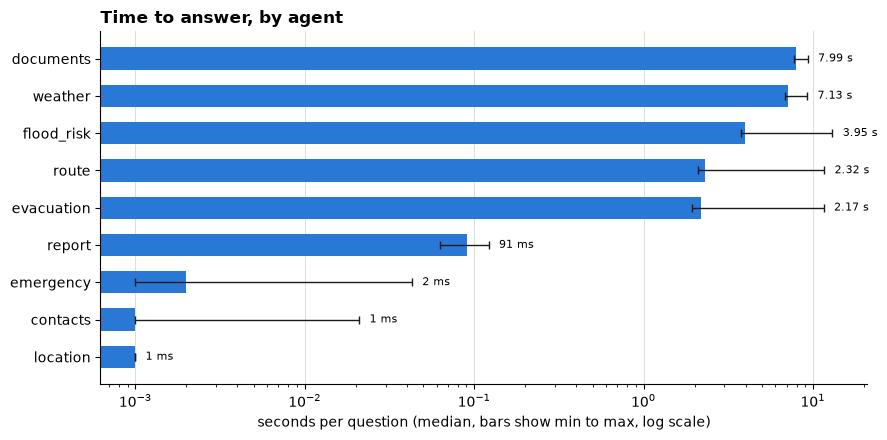

In [9]:
ordered = summary.sort_values("median_s")
fig, axis = plt.subplots(figsize=(9, 4.5))
positions = range(len(ordered))
axis.barh(list(positions), ordered["median_s"], color="#2a78d6", height=0.6)
axis.errorbar(ordered["median_s"], list(positions),
              xerr=[ordered["median_s"] - ordered["min_s"], ordered["max_s"] - ordered["median_s"]],
              fmt="none", ecolor="#1c1b19", elinewidth=1, capsize=3)
for position, (agent, row) in enumerate(ordered.iterrows()):
    label = f"{row['median_s'] * 1000:.0f} ms" if row["median_s"] < 0.1 else f"{row['median_s']:.2f} s"
    axis.text(row["max_s"] * 1.15, position, label, va="center", fontsize=8)
axis.set_yticks(list(positions), ordered.index)
axis.set_xscale("log")  # agents range from milliseconds to many seconds
axis.set_xlabel("seconds per question (median, bars show min to max, log scale)")
axis.set_title("Time to answer, by agent", loc="left", fontweight="bold")
axis.spines[["top", "right"]].set_visible(False)
axis.grid(axis="x", color="#d9d8d4", linewidth=0.6)
axis.set_axisbelow(True)
fig.tight_layout()

In [10]:
# Did every run give a real answer? Failures (model refusals, errors) make timings misleading.
results[results["mode"] == "cold"].groupby("agent").agg(fallback_runs=("fallback", "sum"), sample_answer=("answer", "first")).reindex([a for a, _ in QUESTIONS])

,fallback_runs,sample_answer
agent,,
emergency,0,"If you or someone is in danger, call 911 now. ..."
report,0,Thank you. Your flood report for Brgy. Malanda...
route,0,I cannot calculate a route right now. Head tow...
evacuation,0,Nearest evacuation centers to Pasig (flood ris...
contacts,0,Emergency numbers for Quezon City: - National ...
location,0,Got it: Marikina. Ask me for the nearest evacu...
flood_risk,0,"Flood risk for Marikina: LOW (as of Oct 28, 09..."
weather,0,"For Quezon City - tomorrow, Oct 29: * Per PAG..."
documents,0,"For flooding before a typhoon, you can: - Mak..."


## 5. What drives the slow agents?
**Reasoning effort.** Muse is a reasoning model, so most of its time can be hidden thinking. `reasoning_effort="minimal"` trades depth for speed. Compare it for the two agents that call the model.

In [11]:
MODEL_AGENTS = [(agent, question) for agent, question in QUESTIONS if agent in ("weather", "documents")]

effort_frames = []
for effort in (None, "minimal"):
    frame = run_benchmark(make_graph(make_llm(effort)), MODEL_AGENTS, runs=3, warm=False)
    frame["reasoning_effort"] = effort or "default"
    effort_frames.append(frame)
effort_results = pd.concat(effort_frames)

effort_results.groupby(["agent", "reasoning_effort"]).agg(
    median_total_s=("total_s", "median"), median_model_s=("model_s", "median"),
    median_output_tokens=("output_tokens", "median"), fallback_runs=("fallback", "sum"),
).round(2)

done: weather


done: documents


done: weather


done: documents


median_total_s  median_model_s  \
agent     reasoning_effort                                   
documents default                     8.99            8.75   
          minimal                     2.14            2.03   
weather   default                     6.19            5.12   
          minimal                     3.35            1.97   

                            median_output_tokens  fallback_runs  
agent     reasoning_effort                                       
documents default                         2674.0              0  
          minimal                          506.0              0  
weather   default                         1519.0              0  
          minimal                          324.0              0

**Cross-encoder reranking.** The real documents agent reranks candidates with `BAAI/bge-reranker-v2-m3` (about 2 GB, downloaded on first use). The runs above skip it. Set the flag below to include it.

In [12]:
RUN_RERANKER_COMPARISON = True  # downloads BAAI/bge-reranker-v2-m3 the first time

if RUN_RERANKER_COMPARISON:
    os.environ["RERANKER_MODEL"] = "BAAI/bge-reranker-v2-m3"
    load_start = time.perf_counter()
    from src.rag import reranking
    reranking.get_cross_encoder()
    print(f"reranker load: {time.perf_counter() - load_start:.1f} s (not included below)")
    reranked = run_benchmark(graph, [q for q in QUESTIONS if q[0] == "documents"], runs=3, warm=False)
    os.environ["RERANKER_MODEL"] = "none"
    print("documents agent, with reranker:")
    display(reranked[["total_s", "model_s", "other_s", "fallback"]].describe().loc[["min", "50%", "max"]].round(2))

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 7/393 [00:00<00:13, 28.15it/s]

Loading weights:   3%|▎         | 10/393 [00:00<00:17, 21.56it/s]

Loading weights:   4%|▍         | 17/393 [00:00<00:22, 16.69it/s]

Loading weights:   8%|▊         | 33/393 [00:01<00:10, 34.10it/s]

...

Loading weights:  58%|█████▊    | 227/393 [00:15<00:15, 10.58it/s]

Loading weights: 100%|██████████| 393/393 [00:15<00:00, 24.79it/s]

reranker load: 45.0 s (not included below)


done: documents
documents agent, with reranker:


,total_s,model_s,other_s
min,27.34,8.71,18.63
50%,28.12,8.83,18.68
max,30.00,9.43,21.17
